# Validate the NF background against the DC4 simulation

This notebook compares Pascal Janowski's normalizing-flow background sample with the complete three-month DC4 simulated background.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

from astropy.io import fits
import h5py
from tqdm.auto import tqdm

### Input files

In [3]:
dc4_background_data_path = Path(
    "../data/Total_DC4_BG_3months_unbinned_data_filtered_with_SAAcut_withSAAbck.fits"
)

nf_background_data_path = Path("../data/nf_background_3months.hdf5")

In [4]:
for path in (dc4_background_data_path, nf_background_data_path):
    size_gb = path.stat().st_size / 1024**3
    print(f"{path.name}: {size_gb:.2f} GB")

Total_DC4_BG_3months_unbinned_data_filtered_with_SAAcut_withSAAbck.fits: 17.59 GB
nf_background_3months.hdf5: 3.31 GB


### Validate the comparison inputs

Confirm the event counts and identify the variables shared by both files. This reads only metadata, not the full event arrays.

In [5]:
with fits.open(dc4_background_data_path, lazy_load_hdus=True) as file:
    event_header = file[1].header
    dc4_event_count = event_header["NAXIS2"]
    dc4_columns = [
        event_header[f"TTYPE{index}"]
        for index in range(1, event_header["TFIELDS"] + 1)
    ]

with h5py.File(nf_background_data_path, "r") as file:
    nf_columns = list(file.keys())
    nf_event_count = file["TimeTags"].shape[0]

comparison_variables = [
    name for name in ("Energies", "Phi", "Chi local", "Psi local")
    if name in dc4_columns and name in nf_columns
]

print(f"DC4 simulated events: {dc4_event_count:,}")
print(f"NF generated events: {nf_event_count:,}")
print("Comparison variables:", comparison_variables)

DC4 simulated events: 168,648,544
NF generated events: 168,635,152
Comparison variables: ['Energies', 'Phi', 'Chi local', 'Psi local']


## Build the comparison histograms

In [6]:
# Physical ranges from Pascal's checkpoint
energy_range = (100.0, 10_000.0)  # keV
phi_range = (0.0, np.pi)  # radians

# Documented comparison binning
energy_edges = np.geomspace(*energy_range, 101)
phi_edges = np.linspace(*phi_range, 181)

In [7]:
histogram_shape = (len(energy_edges) - 1, len(phi_edges) - 1)
chunk_size = 1_000_000

In [8]:
# Reset before accumulation so this cell is safe to rerun.
nf_counts = np.zeros(histogram_shape, dtype=np.int64)

with h5py.File(nf_background_data_path, "r") as file:
    energies = file["Energies"]
    phi = file["Phi"]

    for start in tqdm(range(0, len(energies), chunk_size)):
        stop = min(start + chunk_size, len(energies))
        block_counts, _, _ = np.histogram2d(
            energies[start:stop], phi[start:stop],
            bins=(energy_edges, phi_edges),
        )
        nf_counts += block_counts.astype(np.int64)

print(f"NF events inside histogram: {nf_counts.sum():,}")
assert nf_counts.sum() == nf_event_count

  0%|          | 0/169 [00:00<?, ?it/s]

NF events inside histogram: 168,635,152


In [9]:
# Reset before accumulation so this cell is safe to rerun.
dc4_counts = np.zeros(histogram_shape, dtype=np.int64)

with fits.open(dc4_background_data_path, memmap=True) as file:
    events = file[1].data

    for start in tqdm(range(0, len(events), chunk_size)):
        stop = min(start + chunk_size, len(events))
        block_counts, _, _ = np.histogram2d(
            events["Energies"][start:stop],
            events["Phi"][start:stop],
            bins=(energy_edges, phi_edges),
        )
        dc4_counts += block_counts.astype(np.int64)

print(f"DC4 events inside histogram: {dc4_counts.sum():,}")
assert dc4_counts.sum() == dc4_event_count

  0%|          | 0/169 [00:00<?, ?it/s]

DC4 events inside histogram: 168,648,544


### Normalized 2D projection: measured energy versus Phi

Reproduce the comparison shown in Pascal's Figure 3.36.

In [10]:
phi_edges_degrees = np.degrees(phi_edges)
bin_areas = (
    np.diff(energy_edges)[:, None]
    * np.diff(phi_edges_degrees)[None, :]
)

nf_density = nf_counts / nf_counts.sum() / bin_areas
dc4_density = dc4_counts / dc4_counts.sum() / bin_areas

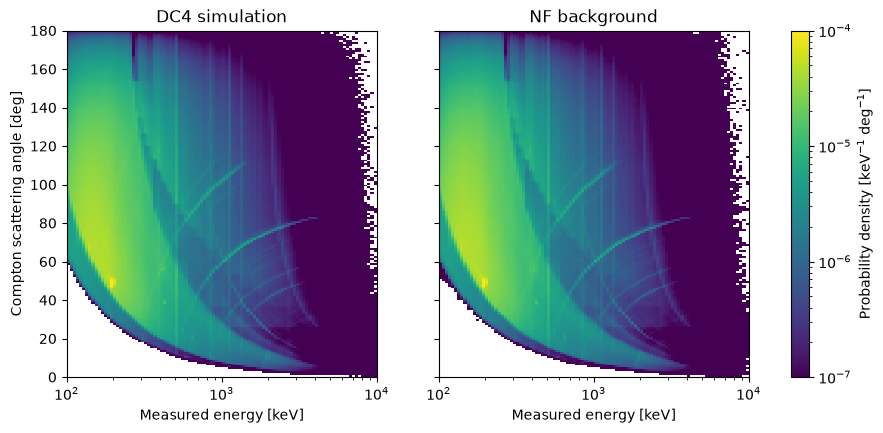

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
color_scale = LogNorm(vmin=1e-7, vmax=1e-4)

for ax, density, title in zip(
    axes,
    (dc4_density, nf_density),
    ("DC4 simulation", "NF background"),
):
    image = ax.pcolormesh(
        energy_edges,
        phi_edges_degrees,
        density.T,
        norm=color_scale,
        shading="auto",
    )
    ax.set_xscale("log")
    ax.set_xlabel("Measured energy [keV]")
    ax.set_title(title)

axes[0].set_ylabel("Compton scattering angle [deg]")
fig.colorbar(image, ax=axes, label=r"Probability density [keV$^{-1}$ deg$^{-1}$]")
plt.show()

### Absolute 1D projections and percent residuals

Reproduce the energy and Phi comparisons shown in Pascal's Figure 3.37.

In [12]:
dc4_energy_counts = dc4_counts.sum(axis=1)
nf_energy_counts = nf_counts.sum(axis=1)

dc4_phi_counts = dc4_counts.sum(axis=0)
nf_phi_counts = nf_counts.sum(axis=0)


In [13]:
energy_residuals = 100 * np.divide(
    nf_energy_counts - dc4_energy_counts,
    dc4_energy_counts,
    out=np.full_like(dc4_energy_counts, np.nan, dtype=float),
    where=dc4_energy_counts > 0,
)

phi_residuals = 100 * np.divide(
    nf_phi_counts - dc4_phi_counts,
    dc4_phi_counts,
    out=np.full_like(dc4_phi_counts, np.nan, dtype=float),
    where=dc4_phi_counts > 0,
)

In [14]:
energy_centers = np.sqrt(energy_edges[:-1] * energy_edges[1:])
phi_centers = 0.5 * (
    phi_edges_degrees[:-1] + phi_edges_degrees[1:]
)

In [15]:
dc4_energy_spectrum = dc4_energy_counts / np.diff(energy_edges)
nf_energy_spectrum = nf_energy_counts / np.diff(energy_edges)

dc4_phi_spectrum = dc4_phi_counts / np.diff(phi_edges_degrees)
nf_phi_spectrum = nf_phi_counts / np.diff(phi_edges_degrees)

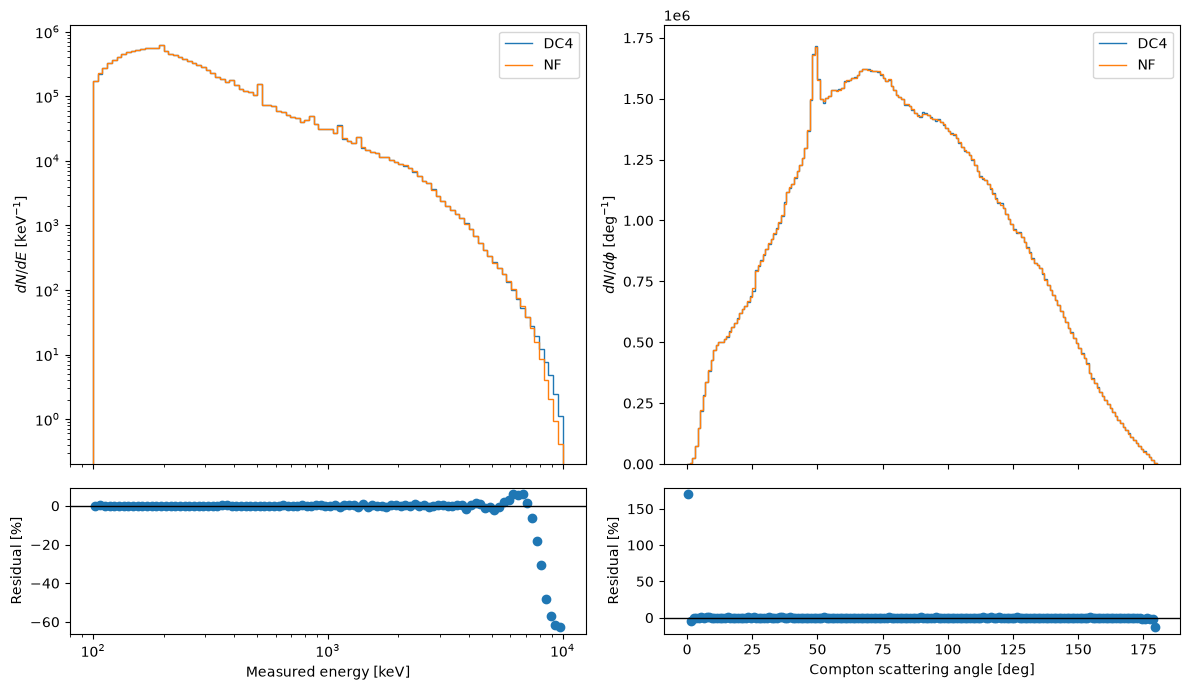

In [18]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 7),
    sharex="col",
    gridspec_kw={"height_ratios": [3, 1]},
)

axes[0, 0].stairs(dc4_energy_spectrum, energy_edges, label="DC4")
axes[0, 0].stairs(nf_energy_spectrum, energy_edges, label="NF")
axes[0, 0].set_xscale("log")
axes[0, 0].set_yscale("log")
axes[0, 0].set_ylabel(r"$dN/dE$ [keV$^{-1}$]")
axes[0, 0].legend()

axes[1, 0].scatter(energy_centers, energy_residuals)
axes[1, 0].axhline(0, color="black", linewidth=1)
axes[1, 0].set_xscale("log")
axes[1, 0].set_xlabel("Measured energy [keV]")
axes[1, 0].set_ylabel("Residual [%]")

axes[0, 1].stairs(dc4_phi_spectrum, phi_edges_degrees, label="DC4")
axes[0, 1].stairs(nf_phi_spectrum, phi_edges_degrees, label="NF")
axes[0, 1].set_ylabel(r"$dN/d\phi$ [deg$^{-1}$]")
axes[0, 1].legend()

axes[1, 1].scatter(phi_centers, phi_residuals)
axes[1, 1].axhline(0, color="black", linewidth=1)
axes[1, 1].set_xlabel("Compton scattering angle [deg]")
axes[1, 1].set_ylabel("Residual [%]")

fig.tight_layout()
plt.show()